<a href="https://colab.research.google.com/github/ivansuarez-AU/MAI510_M5_Assignment_5_1/blob/main/MAI510_M5_Assignment_5_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛍️ RetailVision AI — The Customer Value Detective
## MAI 510 · Module 5 · Assignment 5.1
**Customer Lifetime Value the Established Way**

**Mission:** Become a customer-value detective. Clean actual sales data, estimate future repeat purchases with **BG/NBD**, estimate value per purchase with **Gamma-Gamma**, and identify RetailVision's top 20 customers. Finish with evidence, a Word report draft, a dashboard and a **downloadable ZIP**.

**Important:** The included synthetic dataset is for **practice only**. For assignment submission choose **UCI_REAL** or upload your instructor-provided real dataset. The AI reviewer is **optional** and must not invent results or replace your own analysis.

**Roadmap:** Labs 00–03 setup and input · 04–08 cleaning and RFMT · 09–13 purchase and monetary model · 14–17 12-month value, charts and business decisions · 18–20 optional AI review · 21–23 report and export.

> **Academic integrity:** Model outputs are evidence. Generated report sections contain placeholders where you must write your own interpretation.

### LAB 00 — Student check-in ✅
Enter your **first and last name**. This name goes into all filenames, metadata and Word reports. Set `DEMO_MODE=True` for a quicker instructor walkthrough; set it to `False` for full analysis. `SOURCE='UCI_REAL'` downloads the original Online Retail sample from UCI, `SOURCE='UPLOAD'` asks you for a CSV/XLSX, `SOURCE='DEMO_SYNTHETIC'` makes a reproducible practice dataset.

The full real dataset spans **Dec 2010–Dec 2011**, so its 12-month CLV is an **out-of-sample forecast**, *not* a verified 12-month outcome. The notebook separately tests repeat purchases over a shorter chronological holdout.

In [1]:
from pathlib import Path
import re, json, os, time, hashlib, shutil, warnings
from datetime import datetime, timezone

STUDENT_NAME = input("Enter your FIRST and LAST name (required): ").strip()
if len(STUDENT_NAME.split()) < 2 or len(re.sub(r'[^A-Za-z]', '', STUDENT_NAME)) < 4:
    raise ValueError("Please enter your first AND last name before continuing.")
SAFE_NAME = re.sub(r'[^A-Za-z0-9]+', '_', STUDENT_NAME).strip('_')
DEMO_MODE = True                 # False = use all available real customers
SOURCE = 'UCI_REAL'              # 'UCI_REAL', 'UPLOAD', or 'DEMO_SYNTHETIC'
MONTHLY_DISCOUNT_RATE = 0.01    # 1% per month; explicitly disclose in report
HOLDOUT_DAYS = 75              # calendar-day holdout for purchase model fit
SEED = 510
RUN_TIME = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')
BASE = Path('/content') / f'MAI510_M5_A51_{SAFE_NAME}_{RUN_TIME}'
DIRS = {k: BASE/k for k in ['original_data','clean_data','tables','figures','dashboards','models','reports','proof','ai_review']}
for d in DIRS.values(): d.mkdir(parents=True, exist_ok=True)
RUN_INFO={'student_name': STUDENT_NAME, 'course':'MAI 510', 'module':'5',
          'assignment':'5.1','source':SOURCE,'demo_mode':DEMO_MODE,
          'monthly_discount_rate':MONTHLY_DISCOUNT_RATE,
          'holdout_days':HOLDOUT_DAYS,'created_utc':RUN_TIME,'seed':SEED}
(DIRS['proof']/'student_run_config.json').write_text(json.dumps(RUN_INFO,indent=2))
print('Hello,', STUDENT_NAME, '| Work folder:', BASE)
print('Mode:', 'DEMO/INSTRUCTOR' if DEMO_MODE else 'FULL/STUDENT')

Enter your FIRST and LAST name (required): Ivan Suarez
Hello, Ivan Suarez | Work folder: /content/MAI510_M5_A51_Ivan_Suarez_20261124_223231
Mode: DEMO/INSTRUCTOR


### LAB 01 — Prepare Colab libraries 🧰
The `lifetimes` package implements BG/NBD and Gamma-Gamma. If a package-install error occurs, restart the Colab runtime and run again from LAB 00. The notebook intentionally uses this established library for the **required** models rather than AI-generated substitutes.

In [3]:
%pip -q install 'lifetimes==0.11.3' 'plotly>=5.15' 'python-docx>=1.1' 'openpyxl>=3.1'
import numpy as np, pandas as pd, matplotlib.pyplot as plt, plotly.express as px, plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, HTML
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import summary_data_from_transaction_data
from scipy.stats import pearsonr, spearmanr
from docx import Document
pd.set_option('display.max_columns',30)
np.random.seed(SEED)
print('Libraries loaded. Pandas:',pd.__version__)

Libraries loaded. Pandas: 2.2.3


### LAB 02 — Load source transactions 📥
`UCI_REAL` uses the UCI Online Retail dataset (~22.6 MB download, ~542k invoice lines). First run requires internet. `UPLOAD` accepts CSV or XLSX from your instructor. The original file is retained in the work folder for provenance. `DEMO_SYNTHETIC` generates clearly labeled practice data if downloads fail or for an offline lesson.

**Do not submit synthetic practice results as a real-data assignment.**

In [4]:
import io, urllib.request, zipfile
from google.colab import files

def make_demo_transactions():
    rng=np.random.default_rng(SEED)
    rows=[]
    for i in range(1,551):
        c=f'DEMO-{i:05d}'; first=int(rng.integers(0,125))
        days=sorted(set([first]+[int(x) for x in rng.integers(first,350,size=max(1,int(rng.poisson(5.5)))-1)]))
        unit_base=float(rng.gamma(3.1,14.0)+7)
        for j,d in enumerate(days):
            inv=f'SYN-{i:05d}-{j+1:03d}'
            for k in range(int(rng.integers(1,4))):
                rows.append({'InvoiceNo':inv,'StockCode':'DEMO-ITEM','Description':'Synthetic practice item',
                             'Quantity':int(rng.integers(1,5)),
                             'InvoiceDate':pd.Timestamp('2024-01-01')+pd.Timedelta(days=d,hours=10),
                             'UnitPrice':round(max(1,unit_base*float(rng.lognormal(0,.23))),2),
                             'CustomerID':c,'Country':'DemoLand'})
    return pd.DataFrame(rows)

if SOURCE == 'UCI_REAL':
    url='https://archive.ics.uci.edu/static/public/352/online+retail.zip'
    zip_path=DIRS['original_data']/'UCI_Online_Retail_original.zip'
    print('Downloading official UCI dataset...')
    try:
        urllib.request.urlretrieve(url,str(zip_path))
        with zipfile.ZipFile(zip_path) as z:
            names=[n for n in z.namelist() if n.lower().endswith(('.xlsx','.csv'))]
            if not names: raise RuntimeError('No spreadsheet/CSV found in UCI archive')
            name=names[0]
            print('Reading:',name)
            with z.open(name) as f:
                raw=pd.read_excel(f) if name.lower().endswith('.xlsx') else pd.read_csv(f)
    except Exception as exc:
        raise RuntimeError('UCI download failed. Change SOURCE to UPLOAD and upload the official dataset, or use DEMO_SYNTHETIC for practice only. '+str(exc)) from exc
elif SOURCE == 'UPLOAD':
    uploaded=files.upload()
    if not uploaded: raise ValueError('Upload the CSV or XLSX from your instructor.')
    filename=next(iter(uploaded)); payload=uploaded[filename]
    (DIRS['original_data']/Path(filename).name).write_bytes(payload)
    raw=pd.read_excel(io.BytesIO(payload)) if filename.lower().endswith('.xlsx') else pd.read_csv(io.BytesIO(payload),low_memory=False)
elif SOURCE == 'DEMO_SYNTHETIC':
    raw=make_demo_transactions()
    raw.to_csv(DIRS['original_data']/'DEMO_SYNTHETIC_Online_Retail.csv',index=False)
else:
    raise ValueError('Unknown SOURCE: '+SOURCE)

expected={'InvoiceNo','InvoiceDate','Quantity','UnitPrice','CustomerID'}
missing=expected-set(raw.columns)
if missing: raise ValueError(f'Missing required columns: {missing}. Columns found: {list(raw.columns)}')
print('Raw:',raw.shape, '\nColumns:',list(raw.columns))
display(raw.head())
(DIRS['proof']/'source_summary.json').write_text(json.dumps({'source':SOURCE,'rows':len(raw),'columns':list(raw.columns)},indent=2))

Reading: Online Retail.xlsx
Raw: (541909, 8) 
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


201

### LAB 03 — Audit the raw data 🔎
Before changing anything, inspect missing customer IDs, cancelled invoices (`C` prefix), nonpositive quantities and prices, and exact duplicate invoice lines. These observations become the **cleaning decision log** required by the assignment.

In [5]:
audit = pd.DataFrame([{'Check':'Total invoice lines','Count':len(raw)},
    {'Check':'Missing customer ID','Count':int(raw['CustomerID'].isna().sum())},
    {'Check':'Cancelled invoices (C prefix)','Count':int(raw['InvoiceNo'].astype(str).str.upper().str.startswith('C').sum())},
    {'Check':'Quantity <= 0','Count':int((pd.to_numeric(raw['Quantity'],errors='coerce')<=0).sum())},
    {'Check':'UnitPrice <= 0','Count':int((pd.to_numeric(raw['UnitPrice'],errors='coerce')<=0).sum())},
    {'Check':'Exact duplicate lines','Count':int(raw.duplicated().sum())}])
display(audit)
audit.to_csv(DIRS['tables']/'REQUIRED_initial_data_audit.csv',index=False)
fig=px.bar(audit.iloc[1:],x='Check',y='Count',title='RetailVision | Source data quality checks')
fig.update_layout(xaxis_tickangle=-25);fig.show()
fig.write_html(str(DIRS['dashboards']/'initial_data_audit.html'))

,Check,Count
0,Total invoice lines,541909
1,Missing customer ID,135080
2,Cancelled invoices (C prefix),9288
3,Quantity <= 0,10624
4,UnitPrice <= 0,2517
5,Exact duplicate lines,5268


### LAB 04 — Clean transactions and document the rules 🧼
For this classroom exercise, we **exclude** cancelled invoices, returns (negative quantity), nonpositive prices, missing customer IDs, and exact duplicate lines. Real retailers might separately model returns/refunds; this teaching model forecasts **gross positive-sale revenue** and must disclose that limitation. Treat each invoice as one purchase; multiple lines on the same customer-date are combined to one day for the `lifetimes` model.

In [6]:
df=raw.copy(); decisions=[]
def apply_filter(title, mask, rationale):
    global df
    before=len(df);df=df.loc[mask].copy()
    decisions.append({'Rule':title,'Before':before,'Removed':before-len(df),'After':len(df),'Reason':rationale})
apply_filter('CustomerID required',df['CustomerID'].notna(),'Cannot assign anonymous sales to a named customer')
apply_filter('Valid dates',pd.to_datetime(df['InvoiceDate'],errors='coerce').notna(),'Date is necessary for chronological modeling')
df['InvoiceDate']=pd.to_datetime(df['InvoiceDate'])
apply_filter('Exclude cancelled invoices',~df['InvoiceNo'].astype(str).str.upper().str.startswith('C'),'Exclude recorded cancellations/returns')
df['Quantity']=pd.to_numeric(df['Quantity'],errors='coerce')
df['UnitPrice']=pd.to_numeric(df['UnitPrice'],errors='coerce')
apply_filter('Positive quantity & unit price',(df['Quantity']>0)&(df['UnitPrice']>0),'Analyze positive retail purchase revenue only')
before=len(df);df=df.drop_duplicates().copy()
decisions.append({'Rule':'Remove exact duplicates','Before':before,'Removed':before-len(df),'After':len(df),'Reason':'Avoid double-counting identical lines; may remove legitimate identical purchase lines'})
df['CustomerID']=df['CustomerID'].astype(str).str.replace(r'\.0$','',regex=True).str.strip()
df['Revenue']=df['Quantity']*df['UnitPrice']
apply_filter('Plausible positive sale revenue',np.isfinite(df['Revenue'])&(df['Revenue']>0),'Remove invalid monetary observations')
logs=pd.DataFrame(decisions);display(logs)
logs.to_csv(DIRS['tables']/'REQUIRED_cleaning_decision_log.csv',index=False)
df.to_csv(DIRS['clean_data']/'cleaned_positive_invoice_lines.csv',index=False)
print('Clean invoice lines:',len(df),'Customers:',df['CustomerID'].nunique())

,Rule,Before,Removed,After,Reason
0,CustomerID required,541909,135080,406829,Cannot assign anonymous sales to a named customer
1,Valid dates,406829,0,406829,Date is necessary for chronological modeling
2,Exclude cancelled invoices,406829,8905,397924,Exclude recorded cancellations/returns
3,Positive quantity & unit price,397924,40,397884,Analyze positive retail purchase revenue only
4,Remove exact duplicates,397884,5192,392692,Avoid double-counting identical lines; may rem...
5,Plausible positive sale revenue,392692,0,392692,Remove invalid monetary observations


Clean invoice lines: 392692 Customers: 4338


### LAB 05 — Convert invoice lines into transactions 📅
One invoice may have multiple product lines. We first sum lines by invoice, then consolidate multiple invoices for the same customer on the same **calendar day**, matching the daily time unit used by `lifetimes`. Save both intermediate tables; these preserve the audit trail.

In [7]:
invoices=(df.groupby(['CustomerID','InvoiceNo'],as_index=False)
          .agg(InvoiceDate=('InvoiceDate','min'),Sales=('Revenue','sum')))
invoices['PurchaseDate']=pd.to_datetime(invoices['InvoiceDate']).dt.normalize()
purchases=(invoices.groupby(['CustomerID','PurchaseDate'],as_index=False)['Sales'].sum()
           .sort_values(['CustomerID','PurchaseDate']))
invoices.to_csv(DIRS['clean_data']/'cleaned_invoice_transactions.csv',index=False)
purchases.to_csv(DIRS['clean_data']/'customer_daily_purchases.csv',index=False)
print('Unique invoices:',len(invoices),'Unique customer-purchase days:',len(purchases))
display(purchases.head(8))

Unique invoices: 18532 Unique customer-purchase days: 16763


,CustomerID,PurchaseDate,Sales
0,12346,2011-01-18,77183.60
1,12347,2010-12-07,711.79
2,12347,2011-01-26,475.39
3,12347,2011-04-07,636.25
4,12347,2011-06-09,382.52
5,12347,2011-08-02,584.91
6,12347,2011-10-31,1294.32
7,12347,2011-12-07,224.82


### LAB 06 — Set a historical cutoff and optional demo subsample ⏱️
To assess purchasing fit against **unseen** repeat purchases, hold out the final 75 days (configurable). Everything fitted below uses earlier purchases only. Customers who first appear in the holdout have no history at prediction time and are **not** eligible for the historical-cohort evaluation. The twelve-month output is a forecast **from the cutoff**.

In [8]:
last_day=purchases['PurchaseDate'].max()
cutoff=last_day-pd.Timedelta(days=HOLDOUT_DAYS)
historical=purchases[purchases['PurchaseDate']<=cutoff].copy()
future=purchases[purchases['PurchaseDate']>cutoff].copy()
if DEMO_MODE:
    keep_ids=sorted(historical['CustomerID'].unique())[:min(650,historical['CustomerID'].nunique())]
    historical=historical[historical['CustomerID'].isin(keep_ids)].copy()
    future=future[future['CustomerID'].isin(keep_ids)].copy()
assert historical['PurchaseDate'].max()<=cutoff
assert future.empty or future['PurchaseDate'].min()>cutoff
assert historical['CustomerID'].nunique()>=25,'Not enough historical customers for the probabilistic demo.'
print('Historical cutoff:',cutoff.date(),'| Last observed:',last_day.date())
print('Training customers:',historical['CustomerID'].nunique(),'| Holdout days:',HOLDOUT_DAYS)
historical.to_csv(DIRS['clean_data']/'CALIBRATION_daily_purchases.csv',index=False)
future.to_csv(DIRS['clean_data']/'HOLDOUT_daily_purchases.csv',index=False)
RUN_INFO.update({'cutoff':str(cutoff.date()),'final_date':str(last_day.date()),
                 'training_customers':int(historical['CustomerID'].nunique())})
(DIRS['proof']/'student_run_config.json').write_text(json.dumps(RUN_INFO,indent=2))

Historical cutoff: 2011-09-25 | Last observed: 2011-12-09
Training customers: 650 | Holdout days: 75


334

### LAB 07 — Create one RFMT row per customer 📋
`frequency`: qualifying **repeat** transaction days (the first day does not count). `recency`: days from first purchase to last purchase. `T`: days from first purchase to cutoff. `monetary_value`: average daily-purchase revenue among **repeat** purchases (0 for one-time customers). These definitions are *not* identical to the popular marketing shorthand “days since last visit.”

In [9]:
summary=summary_data_from_transaction_data(
    historical, customer_id_col='CustomerID', datetime_col='PurchaseDate',
    monetary_value_col='Sales', observation_period_end=cutoff, freq='D')
summary.index=summary.index.astype(str)
summary=summary.rename(columns={'frequency':'frequency','recency':'recency','T':'T','monetary_value':'monetary_value'})
assert (summary['frequency']>=0).all() and (summary['recency']<=summary['T']+1e-8).all()
summary.to_csv(DIRS['tables']/'REQUIRED_customer_RFMT_summary.csv',index_label='CustomerID')
print('Customer-level RFMT:');display(summary.head(10))
print('Single-purchase customers:',int((summary.frequency==0).sum()))

Customer-level RFMT:


,frequency,recency,T,monetary_value
CustomerID,,,,
12346,0.0,0.0,250.0,0.0000
12347,4.0,238.0,292.0,519.7675
12348,3.0,283.0,283.0,301.4800
12350,0.0,0.0,235.0,0.0000
12352,4.0,216.0,221.0,407.8900
12353,0.0,0.0,129.0,0.0000
12354,0.0,0.0,157.0,0.0000
12355,0.0,0.0,139.0,0.0000
12356,1.0,80.0,250.0,481.4600


Single-purchase customers: 285


### LAB 08 — Explore RFM and customer behavior 📊
Look for skewed transaction values, repeat purchasers vs one-time purchasers, and the range of customer ages. **Question:** Does being an expensive customer in the past guarantee future value?

In [10]:
fig=make_subplots(rows=2,cols=2,subplot_titles=['Repeat purchase frequency','Customer age (days)','Recency (days)','Average repeat value'])
for j,col in enumerate(['frequency','T','recency','monetary_value']):
    fig.add_trace(go.Histogram(x=summary[col],name=col,nbinsx=35),row=j//2+1,col=j%2+1)
fig.update_layout(height=750,title='RetailVision | Customer RFMT explorer',showlegend=False)
fig.show();fig.write_html(str(DIRS['dashboards']/'REQUIRED_RFMT_explorer.html'))
summary[['frequency','recency','T','monetary_value']].describe().to_csv(DIRS['tables']/'RFMT_descriptive_statistics.csv')

In [14]:

# MAI 510 - MODULE 5 - ASSIGNMENT 5.1
# LAB 09 - CUSTOMER DATA VALIDATION DIAGNOSTIC

import pandas as pd
import numpy as np
from IPython.display import display

print("=" * 60)
print("BG/NBD CUSTOMER DATA DIAGNOSTIC")
print("=" * 60)

checks = {
    "Negative frequency": (summary["frequency"] < 0),
    "Negative recency": (summary["recency"] < 0),
    "Negative customer age": (summary["T"] < 0),
    "Zero customer age (valid)": (summary["T"] == 0),
    "Recency greater than T": (
        summary["recency"] > summary["T"] + 1e-8
    ),
    "Missing required values": (
        summary[["frequency", "recency", "T"]]
        .isna().any(axis=1)
    ),
    "Non-finite values": (
        ~np.isfinite(
            summary[["frequency", "recency", "T"]]
            .to_numpy(dtype=float)
        ).all(axis=1)
    )
}

diagnostics = pd.DataFrame([
    {"Check": name, "Customers": int(mask.sum())}
    for name, mask in checks.items()
])

display(diagnostics)

print("\nCustomers with T = 0:")
display(
    summary.loc[
        summary["T"] == 0,
        ["frequency", "recency", "T"]
    ].head(10)
)

print("\nDiagnostic completed.")


BG/NBD CUSTOMER DATA DIAGNOSTIC


,Check,Customers
0,Negative frequency,0
1,Negative recency,0
2,Negative customer age,0
3,Zero customer age (valid),3
4,Recency greater than T,0
5,Missing required values,0
6,Non-finite values,0



Customers with T = 0:


,frequency,recency,T
CustomerID,,,
12488,0.0,0.0,0.0
12783,0.0,0.0,0.0
13083,0.0,0.0,0.0



Diagnostic completed.


### LAB 09 — Fit BG/NBD: How many purchases will occur? 🔮
**Beta-Geometric / Negative Binomial Distribution (BG/NBD)** assumes customers purchase at an individual rate while active and may become inactive after a purchase. It estimates expected **repeat purchases**, not guaranteed orders. A modest penalizer can stabilize small samples. The fitting data is **historical only**.

In [17]:

# ============================================================
# CORRECTED BG/NBD INPUT VALIDATION
# Allows T = 0 for customers first observed at the cutoff.
# ============================================================

import numpy as np

required = ["frequency", "recency", "T"]
values = summary[required].to_numpy(dtype=float)

if not np.isfinite(values).all():
    raise ValueError(
        "Missing or non-finite values found in BG/NBD inputs."
    )

invalid = (
    (summary["frequency"] < 0)
    | (summary["recency"] < 0)
    | (summary["T"] < 0)
    | (summary["recency"] > summary["T"] + 1e-8)
    | (
        (summary["frequency"] == 0)
        & (summary["recency"].abs() > 1e-8)
    )
    | (
        (summary["frequency"] > 0)
        & (summary["recency"] <= 0)
    )
)

if invalid.any():
    print("Invalid customer records:")
    display(summary.loc[invalid, required].head(20))

    raise ValueError(
        f"{int(invalid.sum())} invalid customer records "
        "require review."
    )

print("BG/NBD input validation passed.")
print("Customers checked:", len(summary))
print("Customers with T = 0:", int((summary["T"] == 0).sum()))


BG/NBD input validation passed.
Customers checked: 650
Customers with T = 0: 3


In [19]:

# ============================================================
# MAI 510 - MODULE 5 - ASSIGNMENT 5.1
# LAB 09/10 REPAIR - RESTORE BG/NBD PREDICTIONS
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 65)
print("RETAILVISION AI - BG/NBD PREDICTION REPAIR")
print("=" * 65)

# 1. Confirm the customer summary exists.
if "summary" not in globals():
    raise RuntimeError(
        "The customer summary is missing. "
        "Run the customer-summary preparation lab first."
    )

# 2. Confirm the trained model is available.
if "bgf" not in globals() or not hasattr(bgf, "params_"):
    raise RuntimeError(
        "The trained BG/NBD model is not available. "
        "Rerun LAB 09 before continuing."
    )

# 3. Verify the required columns.
required = ["frequency", "recency", "T"]

missing = [
    col for col in required
    if col not in summary.columns
]

if missing:
    raise ValueError(
        f"Required customer features are missing: {missing}"
    )

# 4. Make predictions.
# HOLDOUT_DAYS must use the same time unit as recency and T.
print("\nCalculating expected purchases...")

summary["pred_repeat_holdout"] = (
    bgf.conditional_expected_number_of_purchases_up_to_time(
        HOLDOUT_DAYS,
        summary["frequency"],
        summary["recency"],
        summary["T"]
    )
)

# 5. Calculate probability of being active.
summary["prob_alive"] = (
    bgf.conditional_probability_alive(
        summary["frequency"],
        summary["recency"],
        summary["T"]
    )
)

# 6. Validate results.
assert np.isfinite(
    summary["pred_repeat_holdout"]
).all(), "BG/NBD generated non-finite predictions."

assert (
    summary["pred_repeat_holdout"] >= 0
).all(), "Negative expected purchases detected."

assert (
    summary["prob_alive"].between(0, 1)
).all(), "Invalid customer activity probabilities."

# 7. Save the results.
tables_dir = Path(DIRS["tables"])
tables_dir.mkdir(parents=True, exist_ok=True)

output_file = (
    tables_dir / "REQUIRED_BGNBD_predictions.csv"
)

summary.to_csv(
    output_file,
    index_label="CustomerID"
)

# 8. Display proof.
print("\nPredictions successfully restored!")

display(
    summary[
        [
            "frequency",
            "recency",
            "T",
            "pred_repeat_holdout",
            "prob_alive"
        ]
    ].head(10)
)

print("\nSaved:", output_file)
print("\nREADY FOR LAB 10")


RETAILVISION AI - BG/NBD PREDICTION REPAIR

Calculating expected purchases...

Predictions successfully restored!


,frequency,recency,T,pred_repeat_holdout,prob_alive
CustomerID,,,,,
12346,0.0,0.0,250.0,0.146717,1.0
12347,4.0,238.0,292.0,1.000668,1.0
12348,3.0,283.0,283.0,0.803725,1.0
12350,0.0,0.0,235.0,0.154383,1.0
12352,4.0,216.0,221.0,1.260827,1.0
12353,0.0,0.0,129.0,0.244748,1.0
12354,0.0,0.0,157.0,0.211974,1.0
12355,0.0,0.0,139.0,0.231940,1.0
12356,1.0,80.0,250.0,0.394985,1.0



Saved: /content/MAI510_M5_A51_Ivan_Suarez_20261124_223231/tables/REQUIRED_BGNBD_predictions.csv

READY FOR LAB 10


### LAB 10 — Compare predicted vs actual repeat purchases (required chart) ✅
Holdout counts are unique **purchase days after cutoff** among historical customers. They are future transactions beyond the customer's first purchase, consistent with the BG/NBD repeat-purchase concept. This is a **real holdout chart**, not the model fitting curve. Aggregate by observed count to make the plot interpretable.

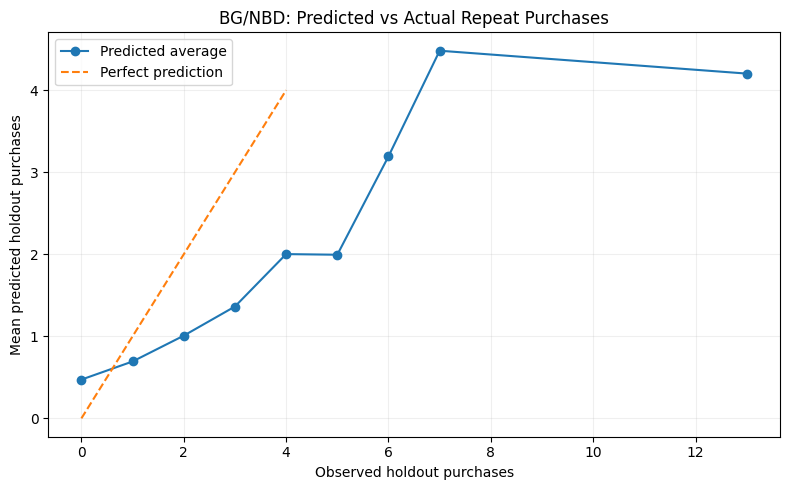

Holdout purchase-count MAE: 0.826


In [20]:
holdout_counts=future.groupby('CustomerID')['PurchaseDate'].nunique()
summary['actual_repeat_holdout']=holdout_counts.reindex(summary.index).fillna(0).astype(int)
fit_stats={'mean_predicted':float(summary['pred_repeat_holdout'].mean()),
           'mean_actual':float(summary['actual_repeat_holdout'].mean()),
           'mae_purchase_counts':float(np.abs(summary['pred_repeat_holdout']-summary['actual_repeat_holdout']).mean())}
fit_table=(summary.groupby('actual_repeat_holdout').agg(customers=('frequency','size'),
            predicted_avg=('pred_repeat_holdout','mean')).reset_index()
           .rename(columns={'actual_repeat_holdout':'observed_repeat_purchases'}))
fit_table=fit_table[fit_table['customers']>=2]
fig=go.Figure()
fig.add_trace(go.Scatter(x=fit_table['observed_repeat_purchases'],y=fit_table['predicted_avg'],mode='lines+markers',name='Predicted average'))
limit=max(2,float(summary['actual_repeat_holdout'].quantile(.95)),float(summary['pred_repeat_holdout'].quantile(.95)))
fig.add_trace(go.Scatter(x=[0,limit],y=[0,limit],mode='lines',name='Perfect calibration',line=dict(dash='dash')))
fig.update_layout(title='Required fit chart: predicted vs observed repeat-purchase counts',
    xaxis_title='Observed holdout purchases per customer',yaxis_title='Mean BG/NBD predicted purchases',height=480)
fig.show();fig.write_html(str(DIRS['dashboards']/'REQUIRED_purchase_model_fit.html'))
fig.write_image(str(DIRS['figures']/'REQUIRED_purchase_model_fit.png')) if False else None
# Portable static PNG without kaleido
plt.figure(figsize=(8,5));plt.plot(fit_table.observed_repeat_purchases,fit_table.predicted_avg,'o-',label='Predicted average')
plt.plot([0,limit],[0,limit],'--',label='Perfect prediction');plt.xlabel('Observed holdout purchases')
plt.ylabel('Mean predicted holdout purchases');plt.title('BG/NBD: Predicted vs Actual Repeat Purchases');plt.legend();plt.grid(alpha=.2)
plt.tight_layout();plt.savefig(DIRS['figures']/'REQUIRED_purchase_model_fit.png',dpi=150);plt.show()
summary[['frequency','recency','T','pred_repeat_holdout','actual_repeat_holdout','prob_alive']].to_csv(
    DIRS['tables']/'REQUIRED_purchase_model_holdout_comparison.csv',index_label='CustomerID')
(DIRS['proof']/'purchase_fit_metrics.json').write_text(json.dumps(fit_stats,indent=2))
print('Holdout purchase-count MAE:',round(fit_stats['mae_purchase_counts'],3))

### LAB 11 — Check the Gamma-Gamma monetary assumption 🔗
The Gamma-Gamma monetary-value model assumes a customer's average transaction value is approximately **independent of their purchase frequency**, conditional on model assumptions. Check the **eligible repeat buyers with positive monetary value**. Pearson correlation measures *linear* association; also inspect the scatterplot and Spearman rank correlation. A non-significant correlation does **not prove** independence.

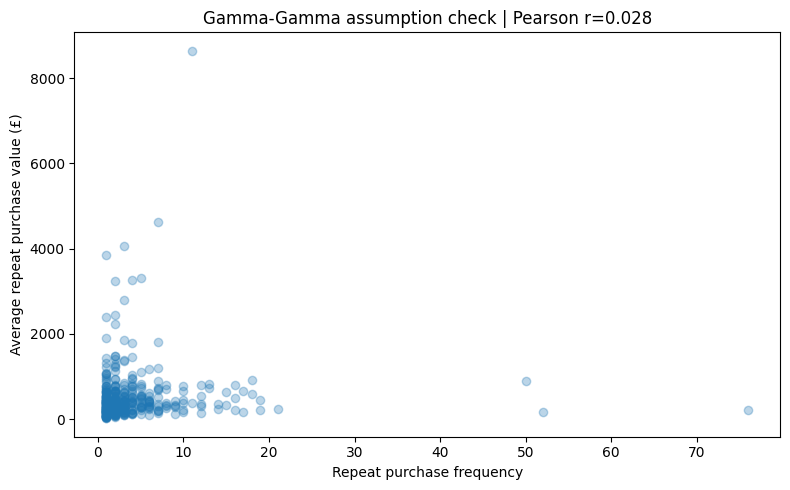

Pearson: 0.0281 (p= 0.5923 ) Spearman: 0.1377


In [21]:
eligible=summary[(summary['frequency']>0)&(summary['monetary_value']>0)].copy()
assert len(eligible)>=20, 'Not enough eligible repeat customers for Gamma-Gamma. Use full data or another source.'
pearson_r,pearson_p=pearsonr(eligible['frequency'],eligible['monetary_value'])
spearman_r,spearman_p=spearmanr(eligible['frequency'],eligible['monetary_value'])
corr={'n_eligible':len(eligible),'pearson_r':float(pearson_r),'pearson_p':float(pearson_p),
      'spearman_r':float(spearman_r),'spearman_p':float(spearman_p),
      'interpretation_note':'Correlation is diagnostic evidence, not a proof of independence.'}
(DIRS['proof']/'REQUIRED_monetary_assumption_correlation.json').write_text(json.dumps(corr,indent=2))
fig=px.scatter(eligible.reset_index(),x='frequency',y='monetary_value',opacity=.55,
    title=f'Gamma-Gamma assumption | Pearson r={pearson_r:.3f}, Spearman rho={spearman_r:.3f}',
    labels={'frequency':'Repeat purchase frequency','monetary_value':'Average repeat purchase value (£)'})
fig.show();fig.write_html(str(DIRS['dashboards']/'REQUIRED_GammaGamma_assumption_scatter.html'))
plt.figure(figsize=(8,5));plt.scatter(eligible.frequency,eligible.monetary_value,alpha=.3)
plt.xlabel('Repeat purchase frequency');plt.ylabel('Average repeat purchase value (£)')
plt.title(f'Gamma-Gamma assumption check | Pearson r={pearson_r:.3f}')
plt.tight_layout();plt.savefig(DIRS['figures']/'REQUIRED_monetary_correlation.png',dpi=150);plt.show()
print('Pearson:',round(pearson_r,4),'(p=',round(pearson_p,4),')','Spearman:',round(spearman_r,4))
if abs(pearson_r)>0.3:
    print('CAUTION: Noticeable frequency-value association: Gamma-Gamma assumption may not hold. Report this limitation explicitly.')

### LAB 12 — Fit Gamma-Gamma: How much is each future purchase worth? 💷
Gamma-Gamma estimates expected **repeat transaction monetary value**, conditioned on eligible repeat buyers. We must not silently present its prediction for ineligible one-time customers as though those customers were observed repeat purchasers. For **all-customer** ranking, the notebook uses the model's population-level monetary expectation as a **clearly marked, assumption-based proxy** for one-time customers; these rows are flagged. This is an educational fallback, not a verified customer-specific monetary forecast.

In [22]:
ggf=GammaGammaFitter(penalizer_coef=0.05 if DEMO_MODE else 0.01)
GG_FIT_OK=True
try:
    ggf.fit(eligible['frequency'],eligible['monetary_value'])
    print('Gamma-Gamma parameters:');display(ggf.params_.to_frame('Estimate'))
    ggf.params_.to_csv(DIRS['tables']/'REQUIRED_GammaGamma_parameters.csv')
    with open(DIRS['models']/'GammaGamma_fitted.pkl','wb') as f:pickle.dump(ggf,f)
    eligible_expected=ggf.conditional_expected_average_profit(eligible['frequency'],eligible['monetary_value'])
    fallback_value=float(np.asarray(ggf.conditional_expected_average_profit(pd.Series([0.0]),pd.Series([0.0]))).reshape(-1)[0])
except Exception as ex:
    GG_FIT_OK=False
    raise RuntimeError('Gamma-Gamma could not be fitted for this dataset. Try full data and review model eligibility/assumptions. Original error: '+str(ex)) from ex
summary['expected_purchase_value']=fallback_value
summary['monetary_estimate_method']='population_prior_one_time_customer'
summary.loc[eligible.index,'expected_purchase_value']=eligible_expected.to_numpy()
summary.loc[eligible.index,'monetary_estimate_method']='customer_GammaGamma_repeat_buyer'
print('Population-level estimate for first-time customers:',round(fallback_value,2))
print(summary['monetary_estimate_method'].value_counts())

Gamma-Gamma parameters:


,Estimate
p,1.484999
q,0.199067
v,1.379273


Population-level estimate for first-time customers: -2.56
monetary_estimate_method
customer_GammaGamma_repeat_buyer      365
population_prior_one_time_customer    285
Name: count, dtype: int64


### LAB 13 — Forecast 12 months and discount future money 💰
We use **monthly** discounting over twelve 30-day periods. Each month’s expected **incremental purchases** comes from the BG/NBD cumulative expectation; multiply by predicted transaction value, then divide by `(1 + monthly_rate)^month`. The result estimates **discounted future gross sales**, not net profit. This approach produces estimates for all historically observed customers, including one-time shoppers with flagged monetary proxies.

In [23]:
horizons=np.arange(1,13)*30.0
prev=np.zeros(len(summary)); discounted=np.zeros(len(summary)); raw_total=np.zeros(len(summary))
monthly_records=[]
for month,day in enumerate(horizons,start=1):
    cumulative=np.asarray(bgf.conditional_expected_number_of_purchases_up_to_time(
        float(day),summary['frequency'],summary['recency'],summary['T']),dtype=float)
    extra=np.maximum(0,cumulative-prev)
    money=extra*summary['expected_purchase_value'].to_numpy(dtype=float)
    discounted+=money/((1+MONTHLY_DISCOUNT_RATE)**month)
    raw_total+=money
    monthly_records.append({'month':month,'total_expected_purchases':float(extra.sum()),
                            'gross_forecast_sales':float(money.sum()),
                            'discounted_forecast_sales':float((money/(1+MONTHLY_DISCOUNT_RATE)**month).sum())})
    prev=cumulative
summary['expected_purchases_12m']=prev
summary['forecast_12m_gross_sales']=raw_total
summary['forecast_12m_discounted_sales_CLV']=discounted
summary=summary.sort_values('forecast_12m_discounted_sales_CLV',ascending=False)
summary['CLV_rank']=np.arange(1,len(summary)+1)
summary.to_csv(DIRS['tables']/'REQUIRED_ALL_customers_12month_CLV.csv',index_label='CustomerID')
pd.DataFrame(monthly_records).to_csv(DIRS['tables']/'twelve_month_forecast_by_month.csv',index=False)
print('Forecast is gross positive-sale revenue (£), DISCOUNT RATE=',MONTHLY_DISCOUNT_RATE,'per month')
print('No observed 12-month future period is available in this dataset; forecast is not a validated 12-month result.')
display(summary.head())

Forecast is gross positive-sale revenue (£), DISCOUNT RATE= 0.01 per month
No observed 12-month future period is available in this dataset; forecast is not a validated 12-month result.


/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning:

invalid value encountered in log



,frequency,recency,T,monetary_value,actual_repeat_holdout,pred_repeat_holdout,prob_alive,expected_purchase_value,monetary_estimate_method,expected_purchases_12m,forecast_12m_gross_sales,forecast_12m_discounted_sales_CLV,CLV_rank
CustomerID,,,,,,,,,,,,,
12415,11.0,238.0,262.0,8643.318182,4,2.767729,1.0,9089.097790,customer_GammaGamma_repeat_buyer,13.285098,120749.555960,113253.800601,1
13089,50.0,294.0,294.0,897.020200,15,10.963327,1.0,906.829741,customer_GammaGamma_repeat_buyer,52.623971,47720.981603,44758.612088,2
12931,7.0,256.0,282.0,4621.957143,4,1.704087,1.0,5008.021578,customer_GammaGamma_repeat_buyer,8.179615,40963.690186,38420.792221,3
13098,18.0,230.0,242.0,927.831111,7,4.741105,1.0,956.570253,customer_GammaGamma_repeat_buyer,22.757304,21768.960390,20417.611309,4
12744,3.0,174.0,243.0,4052.966667,2,0.912671,1.0,4941.895299,customer_GammaGamma_repeat_buyer,4.380820,21649.551617,20305.615059,5


### LAB 14 — Required Top-20 ranking 🏆
RetailVision has a fixed outreach budget. Which twenty customers have the largest *predicted* discounted future gross sales? These are **hypotheses about future behavior**, not guarantees. Save the full list and top-20 separately.

,CLV_rank,frequency,recency,T,monetary_value,prob_alive,expected_purchase_value,monetary_estimate_method,expected_purchases_12m,forecast_12m_gross_sales,forecast_12m_discounted_sales_CLV
CustomerID,,,,,,,,,,,
12415,1,11.000000,238.000000,262.000000,8643.318182,100.00%,9089.097790,customer_GammaGamma_repeat_buyer,13.29,120749.555960,"£113,253.80"
13089,2,50.000000,294.000000,294.000000,897.020200,100.00%,906.829741,customer_GammaGamma_repeat_buyer,52.62,47720.981603,"£44,758.61"
12931,3,7.000000,256.000000,282.000000,4621.957143,100.00%,5008.021578,customer_GammaGamma_repeat_buyer,8.18,40963.690186,"£38,420.79"
13098,4,18.000000,230.000000,242.000000,927.831111,100.00%,956.570253,customer_GammaGamma_repeat_buyer,22.76,21768.960390,"£20,417.61"
12744,5,3.000000,174.000000,243.000000,4052.966667,100.00%,4941.895299,customer_GammaGamma_repeat_buyer,4.38,21649.551617,"£20,305.62"
13081,6,5.000000,228.000000,296.000000,3300.668000,100.00%,3700.069681,customer_GammaGamma_repeat_buyer,5.78,21394.616963,"£20,066.51"
12901,7,16.000000,189.000000,195.000000,800.591875,100.00%,828.609955,customer_GammaGamma_repeat_buyer,24.17,20029.270669,"£18,785.92"
12435,8,1.000000,188.000000,192.000000,3850.900000,100.00%,8362.686373,customer_GammaGamma_repeat_buyer,2.35,19622.472504,"£18,404.37"
12409,9,2.000000,104.000000,107.000000,2432.795000,100.00%,3332.055021,customer_GammaGamma_repeat_buyer,5.86,19535.589709,"£18,322.88"


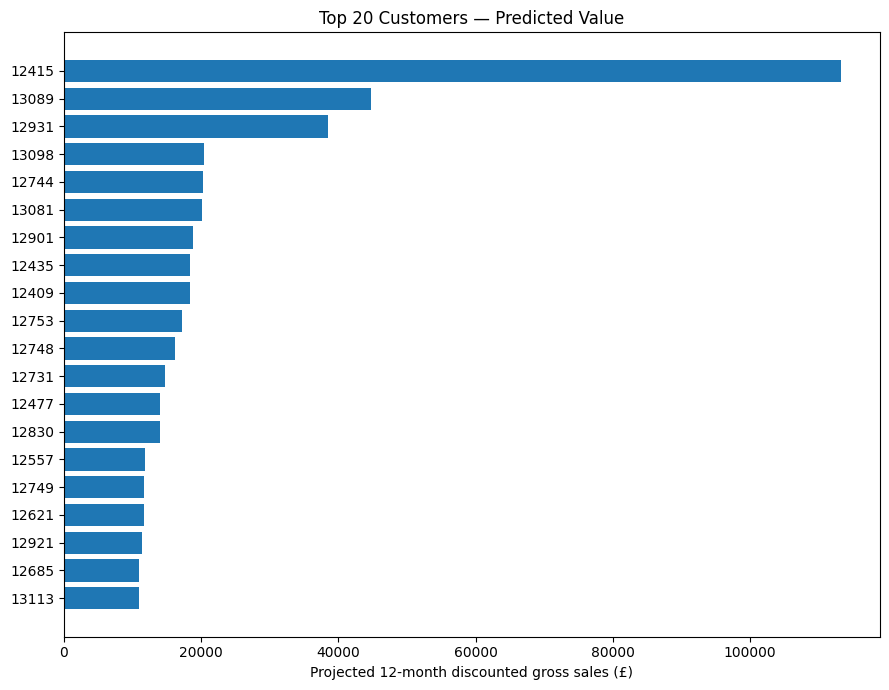

In [24]:
cols=['CLV_rank','frequency','recency','T','monetary_value','prob_alive',
      'expected_purchase_value','monetary_estimate_method','expected_purchases_12m',
      'forecast_12m_gross_sales','forecast_12m_discounted_sales_CLV']
top20=summary[cols].head(20).copy()
top20.to_csv(DIRS['tables']/'REQUIRED_TOP20_customer_CLV.csv',index_label='CustomerID')
display(top20.style.format({'forecast_12m_discounted_sales_CLV':'£{:,.2f}',
                             'expected_purchases_12m':'{:.2f}','prob_alive':'{:.2%}'}))
fig=px.bar(top20.reset_index().sort_values('forecast_12m_discounted_sales_CLV'),
    x='forecast_12m_discounted_sales_CLV',y='CustomerID',orientation='h',
    color='monetary_estimate_method',title='RetailVision | Top 20 projected customer values (£)')
fig.update_layout(height=680);fig.show();fig.write_html(str(DIRS['dashboards']/'REQUIRED_top20_ranking.html'))
plt.figure(figsize=(9,7));plt.barh(top20.index[::-1],top20['forecast_12m_discounted_sales_CLV'].to_numpy()[::-1]);
plt.xlabel('Projected 12-month discounted gross sales (£)');plt.title('Top 20 Customers — Predicted Value');plt.tight_layout()
plt.savefig(DIRS['figures']/'REQUIRED_top20_ranking.png',dpi=150);plt.show()

### LAB 15 — Optional scenario explorer 🎯
How much does the discount rate matter? Compare forecasts at **0%, 1%, and 2% per month**, using the same monthly purchase/value estimates. These are sensitivity analyses; they do not re-fit the models.

In [25]:
scenario_rows=[]
for rate in [0.0,0.01,0.02]:
    # Recompute by customer from cumulative expected repeat purchase counts
    v=np.zeros(len(summary)); prior=np.zeros(len(summary))
    for m in range(1,13):
        cum=np.asarray(bgf.conditional_expected_number_of_purchases_up_to_time(
            m*30.0,summary['frequency'],summary['recency'],summary['T']),dtype=float)
        v+=np.maximum(0,cum-prior)*summary['expected_purchase_value'].to_numpy()/((1+rate)**m)
        prior=cum
    scenario_rows.append({'monthly_discount_rate':rate,'portfolio_CLV':float(v.sum()),
                          'median_customer_CLV':float(np.median(v))})
scenarios=pd.DataFrame(scenario_rows)
display(scenarios)
scenarios.to_csv(DIRS['tables']/'optional_discount_sensitivity.csv',index=False)
px.bar(scenarios,x='monthly_discount_rate',y='portfolio_CLV',title='Sensitivity of forecast value to monthly discount rate').show()

/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning:

invalid value encountered in log



,monthly_discount_rate,portfolio_CLV,median_customer_CLV
0,0.00,NaN,NaN
1,0.01,NaN,NaN
2,0.02,NaN,NaN


### LAB 16 — Executive dashboard 📈
A single interactive dashboard lets you review the customer count, purchase model calibration, top-20 projected customers, and monthly revenue forecast. The saved HTML works **offline** after export.

In [26]:
dashboard=make_subplots(rows=2,cols=2,
    subplot_titles=['Predicted vs actual repeat purchases','Top 20 projected value',
                    'Monthly discounted portfolio value','Frequency distribution'],
    specs=[[{'type':'xy'},{'type':'xy'}],[{'type':'xy'},{'type':'xy'}]])
dashboard.add_trace(go.Scatter(x=fit_table['observed_repeat_purchases'],y=fit_table['predicted_avg'],
    mode='lines+markers',name='Predicted holdout'),row=1,col=1)
dashboard.add_trace(go.Bar(x=top20.index.astype(str),y=top20['forecast_12m_discounted_sales_CLV'],name='Top 20'),row=1,col=2)
monthly_df=pd.DataFrame(monthly_records)
dashboard.add_trace(go.Bar(x=monthly_df.month,y=monthly_df.discounted_forecast_sales,name='Discounted value'),row=2,col=1)
dashboard.add_trace(go.Histogram(x=summary.frequency,nbinsx=30,name='Repeat frequency'),row=2,col=2)
dashboard.update_layout(height=930,width=1150,title=f'RetailVision Executive Dashboard | {STUDENT_NAME}',showlegend=False)
dashboard.show()
dashboard.write_html(str(DIRS['dashboards']/'REQUIRED_RetailVision_Executive_Dashboard.html'),include_plotlyjs=True)
print('Saved standalone HTML dashboard. Interactive values are the current student run, not sample claims.')

Saved standalone HTML dashboard. Interactive values are the current student run, not sample claims.


### LAB 17 — Business questions the student must answer ✍️
Write **one page** (your own words) about what the marketing team should do differently given this ranking. Also write **one paragraph** about what the model could get badly wrong. Consider returns excluded, independence, stationary purchasing, customer acquisition, discount-rate assumptions, and ethical data usage.

In [27]:
MARKETING_ANALYSIS = """[STUDENT WRITING REQUIRED: One page. Name 2-3 concrete marketing actions, explain how the Top-20 ranking supports each, address contact cost and fairness, and distinguish sales from profit.]"""
MODEL_LIMITATIONS = """[STUDENT WRITING REQUIRED: One paragraph. Describe a concrete scenario where BG/NBD and/or Gamma-Gamma assumptions fail and the resulting decision could be harmful or costly.]"""
print('Complete MARKETING_ANALYSIS and MODEL_LIMITATIONS here or in the Word report before submitting.')

Complete MARKETING_ANALYSIS and MODEL_LIMITATIONS here or in the Word report before submitting.


### LAB 18 — Prepare an AI review brief (optional) 🤖
Ollama + Qwen can **review the evidence and challenge your interpretation**, not fabricate analyses. The reviewer receives only **aggregated statistics** and assumptions — no customer IDs or raw customer records. The exact prompt is saved so it can also be pasted into another permitted AI system when Ollama cannot run in Colab.

In [28]:
ai_payload={
 'student':STUDENT_NAME,'dataset_type':SOURCE,'demo_mode':DEMO_MODE,
 'observed_historical_customers':int(len(summary)),
 'training_end':str(cutoff.date()),'holdout_days':HOLDOUT_DAYS,
 'purchase_model':'BG/NBD','fit_holdout_mae_purchase_counts':round(fit_stats['mae_purchase_counts'],4),
 'mean_predicted_holdout_purchases':round(fit_stats['mean_predicted'],4),
 'mean_actual_holdout_purchases':round(fit_stats['mean_actual'],4),
 'value_model':'Gamma-Gamma',
 'monetary_frequency_pearson_r':round(float(pearson_r),4),
 'eligible_repeat_buyers':int(len(eligible)),
 'one_time_population_proxy_customers':int((summary.monetary_estimate_method!='customer_GammaGamma_repeat_buyer').sum()),
 'discount_rate_monthly':MONTHLY_DISCOUNT_RATE,
 'top20_aggregate_discounted_sales':round(float(top20.forecast_12m_discounted_sales_CLV.sum()),2),
 'gross_sales_not_net_profit':True,
 'forecast_horizon_months':12,
 'note':'No observed 12-month future outcome in the UCI dataset; short holdout tests purchasing only.'}
AI_PROMPT="""You are a skeptical graduate-level customer analytics reviewer.
Review ONLY the measurable findings in the JSON below.
Respond with these sections: (1) What the evidence supports, (2) Assumptions likely to fail, (3) Three concrete marketing recommendations with cautions, (4) Three checks to do before deployment, (5) Suggested wording improvements for a student report.
Do not invent statistics or customer records. Do not claim the 12-month forecast has been verified. Gross sales are not profit. Do not state that correlation proves independence. Distinguish practice/demo from production. Keep the student's own writing and judgment central.
EVIDENCE:
"""+json.dumps(ai_payload,indent=2)
(DIRS['ai_review']/'OPTIONAL_AI_REVIEW_EVIDENCE.json').write_text(json.dumps(ai_payload,indent=2))
(DIRS['ai_review']/'OPTIONAL_AI_REVIEW_PROMPT.txt').write_text(AI_PROMPT)
print('AI reviewer prompt and aggregate evidence saved.')
print('Use the prompt in Ollama if enabled, or copy it into an approved AI tool.')

AI reviewer prompt and aggregate evidence saved.
Use the prompt in Ollama if enabled, or copy it into an approved AI tool.


### LAB 19 — Optional Ollama setup in hosted Colab ⚙️
Set `RUN_OLLAMA=True` *only if you want the bonus Qwen review*. Ollama setup can fail on Colab depending on available CPU/GPU memory, network policies, and runtime resources. Installation is not required for the assignment. This section attempts installation, and **gracefully skips** on failure. Using the system script is your choice; check your institution's security guidance before executing an external installer.

In [29]:
RUN_OLLAMA = False  # True enables optional local Qwen3 download/review
QWEN_MODEL='qwen3:0.6b'  # smallest option; larger models require more memory
ollama_ready=False
if RUN_OLLAMA:
    import subprocess, urllib.request, socket
    try:
        executable=shutil.which('ollama')
        if not executable:
            installer=DIRS['ai_review']/'ollama_install.sh'
            urllib.request.urlretrieve('https://ollama.com/install.sh',str(installer))
            install=subprocess.run(['sh',str(installer)],capture_output=True,text=True,timeout=180)
            (DIRS['ai_review']/'ollama_install_log.txt').write_text(install.stdout+'\n'+install.stderr)
            if install.returncode!=0:raise RuntimeError('Ollama install failed; inspect saved installer log')
        server=subprocess.Popen(['ollama','serve'],stdout=(DIRS['ai_review']/'ollama_server.log').open('w'),
                                stderr=subprocess.STDOUT)
        for _ in range(20):
            try:
                with socket.create_connection(('127.0.0.1',11434),timeout=1):
                    ollama_ready=True;break
            except OSError:time.sleep(1)
        if not ollama_ready: raise RuntimeError('Ollama server did not become ready')
        pull=subprocess.run(['ollama','pull',QWEN_MODEL],capture_output=True,text=True,timeout=300)
        (DIRS['ai_review']/'ollama_pull_log.txt').write_text(pull.stdout+'\n'+pull.stderr)
        if pull.returncode!=0:raise RuntimeError('Model pull failed')
        print('Ollama ready:',QWEN_MODEL)
    except Exception as exc:
        ollama_ready=False
        (DIRS['ai_review']/'OLLAMA_SETUP_FAILURE.txt').write_text(str(exc))
        print('Optional Ollama unavailable:',exc,'\nCore assignment continues.')
else:
    print('Ollama skipped. This is OPTIONAL; prompt file still exists.')

Ollama skipped. This is OPTIONAL; prompt file still exists.


### LAB 20 — Optional AI reviewer: challenge the findings, not the student 🧐
Ask Qwen to find limitations and suggest more careful business language. **AI output is not measured evidence.** Read it critically, check claims against exported tables, and write what you accepted, rejected, or corrected. The resulting review and verification template are saved for optional submission.

In [30]:
AI_REVIEW_TEXT='Ollama was not run. The saved prompt may be used with an instructor-approved AI assistant.'
if RUN_OLLAMA and ollama_ready:
    import urllib.request
    try:
        request=urllib.request.Request('http://127.0.0.1:11434/api/generate',
            data=json.dumps({'model':QWEN_MODEL,'prompt':AI_PROMPT,'stream':False,
                             'think':False,'options':{'num_predict':650,'temperature':0.2}}).encode(),
            headers={'Content-Type':'application/json'})
        with urllib.request.urlopen(request,timeout=180) as res:
            parsed=json.loads(res.read().decode())
        AI_REVIEW_TEXT=parsed.get('response','') or 'No model response received.'
    except Exception as exc:
        AI_REVIEW_TEXT='Optional AI call failed: '+str(exc)
(DIRS['ai_review']/'OPTIONAL_QWEN_REVIEW.txt').write_text(AI_REVIEW_TEXT)
(DIRS['ai_review']/'STUDENT_AI_CRITICAL_REVIEW.txt').write_text(
    'AI review used (yes/no): ___\nOne AI recommendation supported by my data: ___\nOne AI claim I corrected or rejected: ___\nMy final independent decision: ___\n')
print(AI_REVIEW_TEXT[:8000])

Ollama was not run. The saved prompt may be used with an instructor-approved AI assistant.


### LAB 21 — Produce Word report draft with your actual results 📝
The Word document embeds the student's name, assignment, measured results, and two required charts. **It does not write the one-page analysis or limitations paragraph for you.** Edit those sections either in the variables in LAB 17 or in Word after downloading. If you edit Word after ZIP export, replace the draft inside your final submitted ZIP.

In [31]:
from docx.shared import Inches,Pt,RGBColor
report=Document();sec=report.sections[0];sec.header.paragraphs[0].text='MAI 510 | RetailVision AI | Module 5'
report.add_heading('Assignment 5.1 — Customer Lifetime Value the Established Way',0)
report.add_paragraph('Student: '+STUDENT_NAME)
report.add_paragraph('Run date (UTC): '+RUN_TIME+'   |   Dataset: '+SOURCE+'   |   Demo mode: '+str(DEMO_MODE))
report.add_heading('1. Method and cleaning decisions',level=1)
report.add_paragraph(f'Cleaned historical customer cohort: {len(summary):,}. Cutoff: {cutoff.date()}. Purchase holdout: {HOLDOUT_DAYS} days. Transactions aggregated by invoice and customer-day.')
for row in decisions: report.add_paragraph(f"{row['Rule']}: {row['Removed']:,} rows removed — {row['Reason']}",style='List Bullet')
report.add_heading('2. Repeat purchase model — BG/NBD',level=1)
report.add_paragraph(f"Holdout purchase-count MAE: {fit_stats['mae_purchase_counts']:.3f}. Mean predicted: {fit_stats['mean_predicted']:.3f}; mean observed: {fit_stats['mean_actual']:.3f}.")
report.add_picture(str(DIRS['figures']/'REQUIRED_purchase_model_fit.png'),width=Inches(5.7))
report.add_heading('3. Monetary model — Gamma-Gamma',level=1)
report.add_paragraph(f'Eligible repeat buyers: {len(eligible):,}. Pearson r={pearson_r:.3f} (p={pearson_p:.3g}); Spearman rho={spearman_r:.3f}. Correlation does not establish independence.')
report.add_picture(str(DIRS['figures']/'REQUIRED_monetary_correlation.png'),width=Inches(5.7))
report.add_heading('4. 12-month ranking and discounting',level=1)
report.add_paragraph(f'Monthly discount rate: {MONTHLY_DISCOUNT_RATE:.1%}; horizon: 12 months. Values measure expected discounted gross positive-sale revenue, not net profit. One-time shoppers use flagged population monetary estimates.')
report.add_paragraph('Complete ranked lists: REQUIRED_TOP20_customer_CLV.csv; REQUIRED_ALL_customers_12month_CLV.csv')
report.add_picture(str(DIRS['figures']/'REQUIRED_top20_ranking.png'),width=Inches(5.7))
report.add_heading('5. Marketing recommendations — ONE PAGE REQUIRED',level=1)
report.add_paragraph(MARKETING_ANALYSIS)
report.add_heading('6. When the model would be seriously wrong — ONE PARAGRAPH REQUIRED',level=1)
report.add_paragraph(MODEL_LIMITATIONS)
report.add_heading('7. Optional AI review and human verification',level=1)
report.add_paragraph('AI review status: '+('Attempted' if RUN_OLLAMA else 'Not run (optional)')+'. Any AI suggestions require student verification against metrics.')
report.add_paragraph('This run used synthetic practice data.' if SOURCE=='DEMO_SYNTHETIC' else 'This run used a retail data source specified above.')
report_path=DIRS['reports']/f'{SAFE_NAME}_MAI510_M5_Assignment_5_1_Report_DRAFT.docx'
report.save(report_path)
print('Saved named report:',report_path)
print('Reminder: complete both required writing sections and replace DRAFT with final edited report.')

Saved named report: /content/MAI510_M5_A51_Ivan_Suarez_20261124_223231/reports/Ivan_Suarez_MAI510_M5_Assignment_5_1_Report_DRAFT.docx
Reminder: complete both required writing sections and replace DRAFT with final edited report.


### LAB 22 — Evidence checklist and optional notebook upload 📦
This audit checks the required deliverables exist. **Google Colab cannot automatically capture your current edited notebook reliably**, so download your executed `.ipynb` using **File → Download → Download .ipynb**. You may upload it here to include it in the final ZIP. If you edit the Word report outside Colab, upload the completed report too.

In [32]:
from google.colab import files
REQUIRED_FILES=[
  DIRS['tables']/'REQUIRED_initial_data_audit.csv',
  DIRS['tables']/'REQUIRED_cleaning_decision_log.csv',
  DIRS['tables']/'REQUIRED_customer_RFMT_summary.csv',
  DIRS['tables']/'REQUIRED_BGNBD_parameters.csv',
  DIRS['tables']/'REQUIRED_purchase_model_holdout_comparison.csv',
  DIRS['proof']/'REQUIRED_monetary_assumption_correlation.json',
  DIRS['tables']/'REQUIRED_GammaGamma_parameters.csv',
  DIRS['tables']/'REQUIRED_TOP20_customer_CLV.csv',
  DIRS['tables']/'REQUIRED_ALL_customers_12month_CLV.csv',
  DIRS['figures']/'REQUIRED_purchase_model_fit.png',
  DIRS['figures']/'REQUIRED_monetary_correlation.png',
  DIRS['figures']/'REQUIRED_top20_ranking.png',
  DIRS['dashboards']/'REQUIRED_RetailVision_Executive_Dashboard.html',
  report_path]
status=pd.DataFrame([{'File':str(p.relative_to(BASE)),'Exists':p.exists(),
                     'Size_bytes':p.stat().st_size if p.exists() else 0} for p in REQUIRED_FILES])
display(status)
assert status['Exists'].all(),'Missing artifacts. Rerun the indicated lab before exporting.'
status.to_csv(DIRS['proof']/'REQUIRED_artifact_checklist.csv',index=False)
UPLOAD_EXECUTED_NOTEBOOK_OR_FINAL_REPORT = False  # Set True to upload your executed .ipynb / revised .docx
if UPLOAD_EXECUTED_NOTEBOOK_OR_FINAL_REPORT:
    provided=files.upload()
    for filename,payload in provided.items():
        dest=DIRS['reports'] if filename.lower().endswith('.docx') else DIRS['proof']
        (dest/Path(filename).name).write_bytes(payload)
print('Required evidence present. Writing placeholders still need human completion.')

,File,Exists,Size_bytes
0,tables/REQUIRED_initial_data_audit.csv,True,168
1,tables/REQUIRED_cleaning_decision_log.csv,True,590
2,tables/REQUIRED_customer_RFMT_summary.csv,True,18879
3,tables/REQUIRED_BGNBD_parameters.csv,True,97
4,tables/REQUIRED_purchase_model_holdout_compari...,True,31524
5,proof/REQUIRED_monetary_assumption_correlation...,True,263
6,tables/REQUIRED_GammaGamma_parameters.csv,True,66
7,tables/REQUIRED_TOP20_customer_CLV.csv,True,3220
8,tables/REQUIRED_ALL_customers_12month_CLV.csv,True,101579
9,figures/REQUIRED_purchase_model_fit.png,True,67597


Required evidence present. Writing placeholders still need human completion.


### LAB 23 — The LAST STEP: create and download your named submission ZIP 🎒
This final cell packages all files under your named work folder, including **original input**, cleaned data, models, tables, figures, interactive offline dashboards, Word draft, optional AI artifacts and any manually uploaded executed notebook. **Submit to your LMS yourself**; this notebook cannot upload directly to an LMS without the institution's own connector or API. For data retention you may separately copy the ZIP to Google Drive.

In [33]:
import zipfile
from google.colab import files
readme=(f'Student: {STUDENT_NAME}\nCourse: MAI 510\nModule 5, Assignment 5.1\n'
        f'Source: {SOURCE}\nDemo mode: {DEMO_MODE}\n'
        f'Cutoff: {cutoff.date()}\n12-month forecast monthly discount rate: {MONTHLY_DISCOUNT_RATE}\n'
        'IMPORTANT: Report is a draft until student completes the one-page marketing analysis and the limitations paragraph.\n'
        'For real-data submission choose UCI_REAL or UPLOAD with approved dataset, not DEMO_SYNTHETIC.\n'
        'Download the executed .ipynb and include it in the submitted ZIP (upload to Lab 22).\n'
        'AI/Ollama is optional and must be independently verified.\n'
        'A twelve-month future outcome was NOT available for validation; purchase model evaluated on short holdout.\n')
(BASE/'README_SUBMISSION.txt').write_text(readme)
zip_path=Path('/content')/f'{SAFE_NAME}_MAI510_M5_Assignment_5_1_Submission_{RUN_TIME}.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for path in BASE.rglob('*'):
        if path.is_file(): z.write(path,arcname=str(path.relative_to(BASE)))
with zipfile.ZipFile(zip_path) as z: assert z.testzip() is None
print('FINAL ZIP:',zip_path,'| MB:',round(zip_path.stat().st_size/1_000_000,2))
print('Before submitting: ensure your written analysis is complete and the executed notebook is included.')
files.download(str(zip_path))
# Optional Google Drive backup - disabled by default; uncomment if approved.
# from google.colab import drive
# drive.mount('/content/drive')
# shutil.copy2(zip_path, '/content/drive/MyDrive/'+zip_path.name)

FINAL ZIP: /content/Ivan_Suarez_MAI510_M5_Assignment_5_1_Submission_20261124_223231.zip | MB: 38.43
Before submitting: ensure your written analysis is complete and the executed notebook is included.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>